# 04 — CatBoost Feature Ablation Experiments

**Question:** Which groups of historical features actually improve prediction of 2014–15 subscription purchases?

This notebook *reads* results produced by `src/experiments.py`; experiments run in reusable Python code, not inside the notebook. All comparisons use the same stratified folds, random seed, and CatBoost configuration. **Only the included features change.**

From the repository root, run:

```bash
python -m src.experiments
```

Optional robustness check (3 seeds; takes about three times as long):

```bash
python -m src.experiments --seeds 42 123 2026
```

Results are written to `data/processed/ablation/`. This command does **not** overwrite the earlier model summary or Kaggle submission.

## 1. Load saved experiment results
Every run generates out-of-fold predictions for labeled training accounts. Test labels and Kaggle leaderboard feedback are not used.

In [10]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd()
if not (ROOT / 'src' / 'experiments.py').exists():
    ROOT = ROOT.parent
RESULTS = ROOT / 'data' / 'processed' / 'ablation'
assert (RESULTS / 'ablation_summary.csv').exists(), (
    'Run python -m src.experiments from the repository root first.'
)

summary = pd.read_csv(RESULTS / 'ablation_summary.csv')
runs = pd.read_csv(RESULTS / 'ablation_runs.csv')
folds = pd.read_csv(RESULTS / 'ablation_folds.csv')
oof = pd.read_csv(RESULTS / 'ablation_oof_predictions.csv', dtype={'account.id': 'string'})
groups = pd.read_csv(RESULTS / 'ablation_feature_groups.csv')
with (RESULTS / 'ablation_config.json').open(encoding='utf-8') as f:
    config = json.load(f)

print('Model:', config['model'])
print('Folds per run:', config['folds'])
print('Seeds:', config['seeds'])
print('Experiments:', len(summary))
print('Labeled accounts:', len(oof))

Model: catboost
Folds per run: 5
Seeds: [42, 123, 2026]
Experiments: 4
Labeled accounts: 6941


## 2. Check what was removed
The experiment names describe **retained** inputs. `no_geography` excludes residential ZIP/city/state/coordinates; historical `sub_last_location` is a subscription preference and stays in that experiment. Columns that do not match known groups are assigned to `other` and remain in the removal experiments.

In [11]:
display(groups.groupby('group').size().rename('feature_count').to_frame())
display(summary[['experiment', 'description', 'n_features', 'n_seeds']])

# Inspect the exact feature names for each experiment when needed:
# print(config['experiments']['no_geography']['features'])

,feature_count
group,
donations,2
geography,5
subscriptions,21
tickets,11


,experiment,description,n_features,n_seeds
0,all_features,Every engineered predictive feature (reference),39,3
1,subscriptions_plus_geography,Subscription history plus geography,26,3
2,no_geography,"Remove residential ZIP, city, state, and coord...",34,3
3,subscriptions_only,Subscription-history features alone,21,3


## 3. Compare overall AUROC
Higher is better. `all_features` is the control: its score should reproduce our previous CatBoost validation result (~0.97139) when using the original seed 42 and five folds.

,experiment,n_features,mean_oof_auc,std_oof_auc,mean_oof_average_precision,delta_auc_vs_full
0,all_features,39,0.97055,0.00192,0.83927,0.00000
1,subscriptions_plus_geography,26,0.96742,0.00166,0.83478,-0.00313
2,no_geography,34,0.96237,0.00387,0.83728,-0.00818
3,subscriptions_only,21,0.95355,0.00071,0.82752,-0.01700


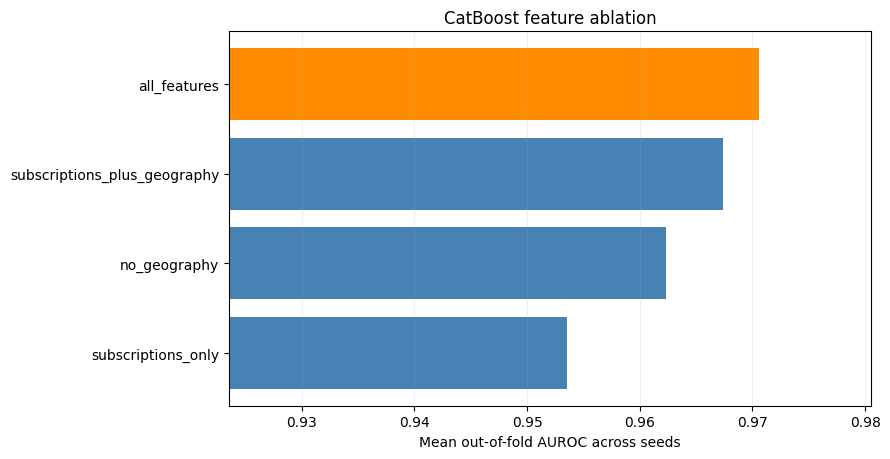

Full-feature CatBoost (seed 42): 0.97139; previous baseline: 0.97139


In [12]:
display(summary[[
    'experiment', 'n_features', 'mean_oof_auc', 'std_oof_auc',
    'mean_oof_average_precision', 'delta_auc_vs_full'
]].round(5))

ordered = summary.sort_values('mean_oof_auc')
fig, ax = plt.subplots(figsize=(9, 4.7))
colors = ['darkorange' if name == 'all_features' else 'steelblue'
          for name in ordered['experiment']]
ax.barh(ordered['experiment'], ordered['mean_oof_auc'], color=colors)
ax.set(xlabel='Mean out-of-fold AUROC across seeds', title='CatBoost feature ablation')
ax.set_xlim(max(0.5, ordered['mean_oof_auc'].min() - 0.03),
            min(1.0, ordered['mean_oof_auc'].max() + 0.01))
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()

if 42 in config['seeds'] and config['folds'] == 5:
    baseline = runs.loc[(runs['seed'] == 42) & (runs['experiment'] == 'all_features'), 'oof_auc'].iloc[0]
    print(f'Full-feature CatBoost (seed 42): {baseline:.5f}; previous baseline: 0.97139')

## 4. Measure the contribution of each feature group
`delta_auc_vs_full = experiment AUROC − all-features AUROC`. A **negative** difference means dropping/limiting features made performance worse. A **positive** difference means the simpler experiment outperformed the full baseline. Treat small differences cautiously, especially with one random seed.

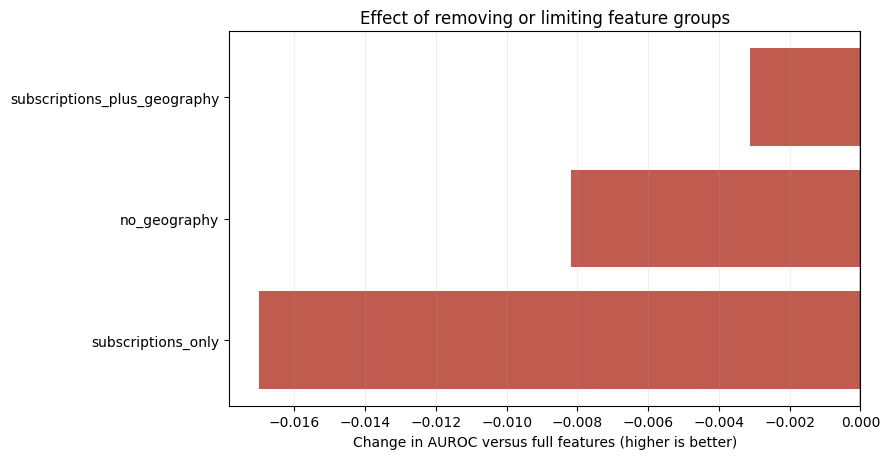

Ablation results (positive = full model benefits from keeping that group):


,experiment,auc_gain_from_keeping_group
2,no_geography,0.00818


In [13]:
compare = summary[summary['experiment'] != 'all_features'].sort_values('delta_auc_vs_full')
fig, ax = plt.subplots(figsize=(9, 4.7))
colors = ['#2d7d46' if d > 0 else '#c05b50' for d in compare['delta_auc_vs_full']]
ax.barh(compare['experiment'], compare['delta_auc_vs_full'], color=colors)
ax.axvline(0, color='black', lw=1)
ax.set(xlabel='Change in AUROC versus full features (higher is better)',
       title='Effect of removing or limiting feature groups')
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()

print('Ablation results (positive = full model benefits from keeping that group):')
removed = summary[summary['experiment'].str.startswith('no_')].copy()
removed['auc_gain_from_keeping_group'] = -removed['delta_auc_vs_full']
display(removed[['experiment', 'auc_gain_from_keeping_group']].round(5))

## 5. Repeatability across seeds
If you ran multiple seeds, this checks whether the same feature group consistently helps. Each experiment at a given seed uses exactly the same account-level folds as its full-feature control. With a single seed, use this as a paired-difference table rather than an uncertainty estimate.

seed,42,123,2026
experiment,,,
all_features,0.00000,0.00000,0.00000
no_geography,-0.00792,-0.00633,-0.01029
subscriptions_only,-0.01862,-0.01774,-0.01465
subscriptions_plus_geography,-0.00241,-0.00431,-0.00268


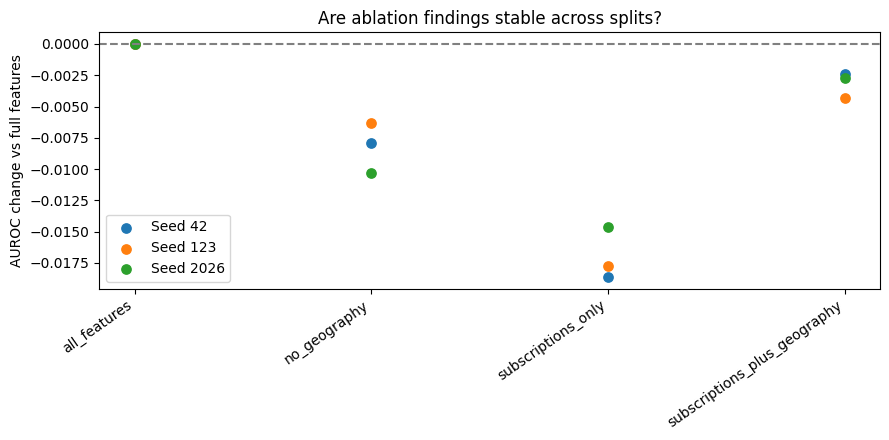

In [14]:
paired = runs.pivot(index='experiment', columns='seed', values='delta_auc_vs_full')
display(paired.round(5))

if len(config['seeds']) > 1:
    plt.figure(figsize=(9, 4.5))
    for seed in paired.columns:
        plt.scatter(paired.index, paired[seed], label=f'Seed {seed}', s=45)
    plt.axhline(0, color='gray', linestyle='--')
    plt.xticks(rotation=35, ha='right')
    plt.ylabel('AUROC change vs full features')
    plt.title('Are ablation findings stable across splits?')
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Only one seed was run. For a stability check: python -m src.experiments --seeds 42 123 2026')

## 6. Test the geography hypothesis more directly
Compare **all features vs no geography**, and **subscriptions alone vs subscriptions + geography**. The second comparison asks whether location provides information beyond subscription history, without other variables contributing. Feature importance alone cannot answer this.

In [15]:
lookup = summary.set_index('experiment')['mean_oof_auc']
pairs = [
    ('all_features', 'no_geography', 'Geography contribution in full model'),
    ('subscriptions_plus_geography', 'subscriptions_only',
     'Geography contribution given subscription history'),
]
for with_geo, without_geo, description in pairs:
    if with_geo in lookup and without_geo in lookup:
        improvement = lookup[with_geo] - lookup[without_geo]
        print(f'{description}: {improvement:+.5f} AUROC')
    else:
        print(f'{description}: run both experiments to compare')

Geography contribution in full model: +0.00818 AUROC
Geography contribution given subscription history: +0.01387 AUROC


## 7. How uncertain are the differences? (Optional paired bootstrap)
Repeatedly resample **accounts**, maintaining the pairing between two models' out-of-fold predictions. The 95% interval describes account-resampling uncertainty for **this particular CV run**; it does not account for all training randomness or guarantee performance on Kaggle's hidden test labels.

In [16]:
def paired_auc_interval(y, full_pred, other_pred, repetitions=300, seed=2026):
    rng = np.random.default_rng(seed)
    differences = []
    for _ in range(repetitions):
        idx = rng.integers(0, len(y), len(y))
        if np.unique(y[idx]).size != 2:
            continue
        differences.append(roc_auc_score(y[idx], full_pred[idx]) -
                           roc_auc_score(y[idx], other_pred[idx]))
    return np.quantile(differences, [0.025, 0.5, 0.975])

chosen_seed = config['seeds'][0]
control = f'pred_all_features_seed_{chosen_seed}'
comparison_names = ['no_geography', 'no_subscriptions', 'no_donations', 'no_tickets']
rows = []
for name in comparison_names:
    candidate = f'pred_{name}_seed_{chosen_seed}'
    if candidate not in oof:
        continue
    low, median, high = paired_auc_interval(
        oof['label'].to_numpy(), oof[control].to_numpy(), oof[candidate].to_numpy()
    )
    rows.append({'Removed group': name.removeprefix('no_'),
                 'Gain from keeping group': median, '95% low': low, '95% high': high})
display(pd.DataFrame(rows).round(5))

,Removed group,Gain from keeping group,95% low,95% high
0,geography,0.00793,0.0022,0.01468


## 8. Does geography matter for both recent subscribers and everyone else?
This is an exploratory subgroup diagnostic using the first seed's OOF predictions. There may be relatively few positive labels in the less-recent group; compare sample sizes before drawing strong conclusions.

In [17]:
geo_column = f'pred_no_geography_seed_{chosen_seed}'
features_file = ROOT / 'data' / 'processed' / 'train_features.csv'
if geo_column in oof and features_file.exists():
    history = pd.read_csv(features_file, dtype={'account.id': 'string'})
    if 'sub_active_2013' in history:
        merged = oof.merge(history[['account.id', 'sub_active_2013']],
                           on='account.id', how='left', validate='one_to_one')
        rows = []
        for active, chunk in merged.groupby('sub_active_2013', dropna=False):
            if chunk['label'].nunique() != 2:
                continue
            rows.append({
                'sub_active_2013': active, 'customers': len(chunk),
                'buyers': int(chunk['label'].sum()),
                'auc_full': roc_auc_score(chunk['label'], chunk[control]),
                'auc_without_geography': roc_auc_score(chunk['label'], chunk[geo_column]),
            })
        result = pd.DataFrame(rows)
        result['geo_auc_gain'] = result['auc_full'] - result['auc_without_geography']
        display(result.round(5))
    else:
        print('sub_active_2013 was not included in the feature table.')
else:
    print('Requires the no_geography experiment and engineered training features.')

,sub_active_2013,customers,buyers,auc_full,auc_without_geography,geo_auc_gain
0,0.0,6596,50,0.83172,0.77864,0.05309
1,1.0,345,282,0.75279,0.75487,-0.00208


## 9. Conclusions and Next Steps

### Main Findings

- **Subscription history is the strongest predictor.** Removing subscription features decreases AUROC from 0.97139 to 0.84589. Subscription history alone achieves 0.95278.
- **Geography provides significant additional predictive information.** Removing geographical features decreases AUROC by 0.00792, with a paired bootstrap 95% interval for the contribution of [0.00220, 0.01468].
- **Geography is particularly helpful for customers without a 2013–14 subscription.** Within this subgroup, AUROC increases from 0.77864 to 0.83172 when geography is included.
- **Donation and ticket features provide limited additional improvement.** Their estimated contributions are small and statistically uncertain.
- **Our baseline was reproduced exactly:** CatBoost achieved 0.97139 out-of-fold AUROC.

### Next Steps

1. Repeat the key experiments across multiple random seeds to assess robustness.
2. Engineer additional geographical and demographic features using the provided ZIP code dataset.
3. Investigate distance to concert venues as a potentially useful predictor.
4. Evaluate new features against our established baseline before proceeding to hyperparameter optimization.